# Laboratorio 9 — Series de tiempo y forecasting
**CC3092 Deep Learning y Sistemas Inteligentes — UVG**

Fernando Andree Hernández Martínez (23645) · Fernando José Rueda Rodas (23748)

Pronóstico *day-ahead* (H = 24 h) del consumo eléctrico horario de clientes de Portugal
(ElectricityLoadDiagrams20112014, UCI). El notebook sigue el pipeline completo:
datos crudos → series horarias limpias → ventanas → tensores → modelos → `backtest()` →
comparación. Los entrenamientos largos se ejecutan con los scripts de `src/` (mismas
funciones que se importan aquí) y sus resultados se guardan en `results/`; este notebook
los carga, los audita y los visualiza.

| Etapa | Script |
|---|---|
| Datos crudos → panel horario | `src/01_prepare_data.py` |
| Baselines StatsForecast | `src/02_baselines.py` |
| LightGBM global | `src/03_lightgbm.py` |
| Modelos propios PyTorch + iteraciones | `src/04_torch_models.py` |
| NeuralForecast (N-HiTS, TCN, PatchTST, iTransformer, DeepAR) | `src/05_neuralforecast.py` |
| Chronos-Bolt zero-shot | `src/06_chronos.py` |
| Reentrenamiento mensual, local vs global, semillas | `src/07_extras.py` |

In [1]:
import sys, inspect, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from IPython.display import Code, display

from src import config as C
from src import data as D
from src.evaluation import (backtest, metrics, mase_scale, daily_origins, summary_row,
                            by_hour_of_day, xmas_mask, to_long_forecasts, Forecaster)
from src.train_torch import Panel, TrainConfig, train_model, get_device
from src import torch_models as TM
from src.utils import load_run, list_runs, ITER_CSV, EPOCH_CSV

SEED = C.SEED                     # reproducibilidad
np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = C.FIG_DIR; FIG.mkdir(parents=True, exist_ok=True)
show = lambda obj: display(Code(inspect.getsource(obj), language="python"))
print("torch", torch.__version__, "| device:", get_device())

torch 2.15.0 | device: mps


## 1. Datos

El crudo trae 140,256 registros cada 15 min (2011–2014) para 370 clientes, en kW.
La variable objetivo es el **consumo por hora en kWh**: kWh = Σ kW·0.25 h de los 4 cuartos.

In [2]:
raw = D.load_raw()
print("crudo:", raw.shape, "|", raw.index[0], "->", raw.index[-1])
raw.iloc[:6, :5]

crudo: (140256, 370) | 2011-01-01 00:15:00 -> 2015-01-01 00:00:00


,MT_001,MT_002,MT_003,MT_004,MT_005
ds,,,,,
2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:30:00,0.0,0.0,0.0,0.0,0.0


In [3]:
show(D.to_hourly)
hourly0 = D.to_hourly(raw)
hourly0.loc["2012-01-01"].iloc[:4, :5]

def to_hourly(raw):
    """kW cada 15 min -> kWh por hora (kWh = sum(kW * 0.25 h)).

    Cada hora agrupa los 4 registros etiquetados HH:00, HH:15, HH:30 y HH:45 y queda
    etiquetada por su inicio. Se eligió esta alineación porque el bloque anómalo de
    los días de cambio de horario ocupa exactamente las etiquetas 01:00-01:45; con
    ella la anomalía cae completa en la hora 01:00 y no contamina horas vecinas.
    Horas incompletas (bordes 2011-01-01 00:00 y 2015-01-01 00:00) quedan como NaN.
    """
    return raw.resample("h").sum(min_count=4) * 0.25

,MT_001,MT_002,MT_003,MT_004,MT_005
ds,,,,,
2012-01-01 00:00:00,3.172589,17.069702,57.993050,103.150406,53.353657
2012-01-01 01:00:00,4.124365,22.581793,77.324066,138.211380,72.256096
2012-01-01 02:00:00,4.758883,23.470839,77.324066,139.227646,67.378052
2012-01-01 03:00:00,4.441625,22.226173,77.324066,110.264229,52.743904


### 1.1 Cambios de horario

Todos los días del crudo tienen 96 registros, aun los de 23 h y 25 h. Inspeccionando el
total del panel alrededor de la 01:00 del último domingo de marzo y de octubre:

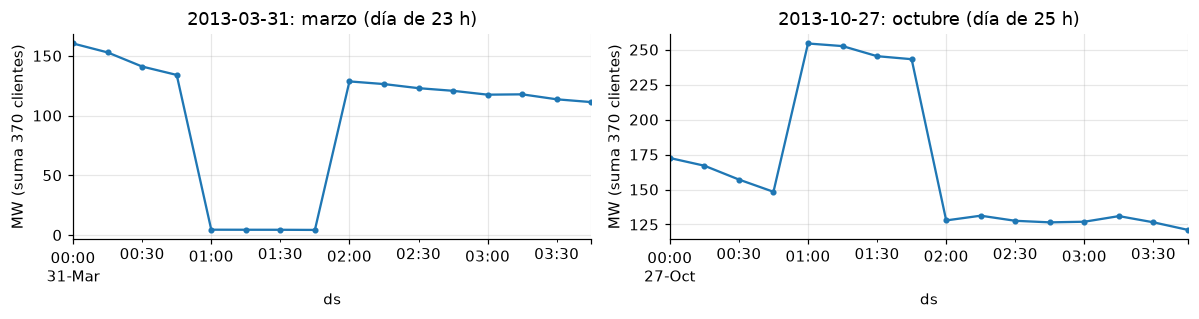

In [4]:
s = raw.sum(axis=1) / 1e3
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for a, d, t in ((ax[0], "2013-03-31", "marzo (día de 23 h)"), (ax[1], "2013-10-27", "octubre (día de 25 h)")):
    s.loc[f"{d} 00:00":f"{d} 03:45"].plot(ax=a, marker="o", ms=3)
    a.set_title(f"{d}: {t}"); a.set_ylabel("MW (suma 370 clientes)")
plt.tight_layout(); plt.savefig(FIG / "dst.png", bbox_inches="tight"); plt.show()

- **Marzo**: los registros 01:00–01:45 vienen en cero (esa hora no existió). Se **imputa**
  la hora 01:00 con el promedio de las horas 00:00 y 02:00 de cada cliente.
- **Octubre**: los registros 01:00–01:45 suman dos horas reales (≈ doble). Se **divide
  entre 2**.

Así cada serie queda en una rejilla regular de 24 h/día (necesaria para ventanas, lags 24/168
y la estacionalidad de MASE) sin un cero falso ni un pico falso que los modelos aprenderían
como patrón. El bloque anómalo ocupa exactamente las etiquetas 01:00–01:45, por eso cada
hora agrupa las etiquetas HH:00–HH:45.

In [5]:
show(D.fix_dst)
hourly = D.fix_dst(hourly0)
for m, d in D.dst_days((2012, 2013, 2014)):
    t = d + pd.Timedelta(hours=1)
    print(d.date(), "01:00 antes:", round(hourly0.loc[t].sum()/1e3, 1), "MWh  -> después:",
          round(hourly.loc[t].sum()/1e3, 1), " | 00:00 =", round(hourly.loc[t - pd.Timedelta(hours=1)].sum()/1e3, 1))

def fix_dst(hourly):
    """Corrige los dos días de cambio de horario.

    El dataset guarda 96 registros en todos los días:
    - marzo (día de 23 h): la hora 01:00 viene en cero para todos los clientes
      -> se imputa con el promedio de las horas 00:00 y 02:00;
    - octubre (día de 25 h): la hora 01:00 acumula dos horas reales
      -> se divide entre 2 (se reparte el consumo).
    Así la serie queda en una rejilla regular de 24 h/día sin huecos ni picos falsos.
    """
    h = hourly.copy()
    for month, day in dst_days():
        t = day + pd.Timedelta(hours=1)
        if t not in h.index:
            continue
        if month == 3:
            prev, nxt = t - pd.Timedelta(hours=1), t + pd.Timedelta(hours=1)
            h.loc[t] = (h.loc[prev] + h.loc[nxt]) / 2
        else:
            h.loc[t] = h.loc[t] / 2
    return h

2012-03-25 01:00 antes: 4.3 MWh  -> después: 130.1  | 00:00 = 144.3
2012-10-28 01:00 antes: 239.6 MWh  -> después: 119.8  | 00:00 = 147.0
2013-03-31 01:00 antes: 4.4 MWh  -> después: 135.8  | 00:00 = 147.0
2013-10-27 01:00 antes: 248.9 MWh  -> después: 124.4  | 00:00 = 161.3
2014-03-30 01:00 antes: 0.5 MWh  -> después: 138.0  | 00:00 = 150.6
2014-10-26 01:00 antes: 267.4 MWh  -> después: 133.7  | 00:00 = 157.0


### 1.2 Filtro del periodo 2012–2014 y subconjunto de clientes

Antes del alta de un cliente (o después de su baja) el crudo rellena con ceros. Un cliente
tiene **datos completos desde 2012-01-01** si dentro de 2012-01-01 → 2014-12-31 no tiene
ninguna racha de ceros de más de 24 h.

In [6]:
show(D.complete_clients)
allc = D.build_hourly()
panel = D.build_panel()
print(f"Clientes tras el filtro 2012–2014: {allc.shape[1]} de {raw.shape[1]}")
print(f"Observaciones horarias por serie: {allc.shape[0]:,}  (1,096 días x 24 h)")
print(f"Panel completo filtrado: {allc.size:,} observaciones")
print(f"Subconjunto usado (semilla {C.SEED}): {panel.shape[1]} clientes -> {panel.size:,} observaciones")

def complete_clients(hourly, start=C.START, end=C.TEST_END, max_zero_run=24):
    """Clientes con datos completos en [start, end]: el crudo rellena con ceros antes
    del alta (y después de una baja), así que se exige que ninguna racha de ceros
    consecutivos dentro del periodo supere `max_zero_run` horas. Esto descarta a
    quienes empiezan después del 2012-01-01, terminan antes de 2015 o tienen apagones
    largos de medición."""
    per = hourly.loc[start:end]
    zero = (per == 0)
    runs = zero.apply(lambda s: s.groupby((~s).cumsum()).sum().max())
    ok = per.notna().all() & (runs <= max_zero_run)
    return ok[ok].index.tolist()

Clientes tras el filtro 2012–2014: 314 de 370
Observaciones horarias por serie: 26,304  (1,096 días x 24 h)
Panel completo filtrado: 8,259,456 observaciones
Subconjunto usado (semilla 42): 100 clientes -> 2,630,400 observaciones


Por cómputo (≈20 modelos × 92 orígenes en una laptop) se usa el subconjunto permitido de
**100 clientes elegidos con semilla 42**, idéntico para todos los modelos.

## 2. Exploración

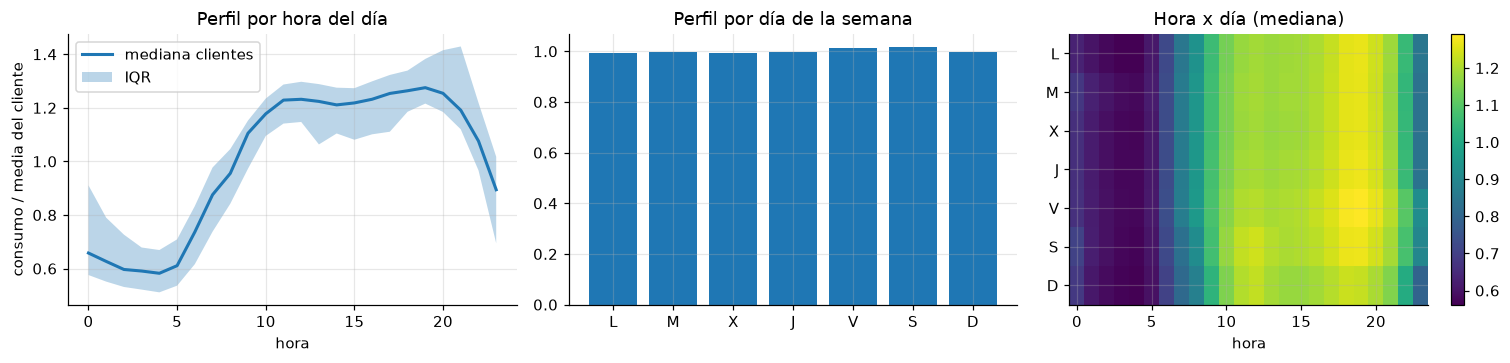

In [7]:
P = Panel()
Y, idx = P.Y, P.index
hol = D.pt_holidays()
norm_load = panel / panel.loc[:C.TRAIN_END].mean()          # cada cliente relativo a su media
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
prof_h = norm_load.groupby(norm_load.index.hour).mean()
ax[0].plot(prof_h.index, prof_h.median(axis=1), lw=2, label="mediana clientes")
ax[0].fill_between(prof_h.index, prof_h.quantile(.25, axis=1), prof_h.quantile(.75, axis=1), alpha=.3, label="IQR")
ax[0].set(title="Perfil por hora del día", xlabel="hora", ylabel="consumo / media del cliente"); ax[0].legend()
dow = norm_load.groupby(norm_load.index.dayofweek).mean().median(axis=1)
ax[1].bar(["L","M","X","J","V","S","D"], dow); ax[1].set(title="Perfil por día de la semana")
hm = norm_load.median(axis=1).groupby([norm_load.index.dayofweek, norm_load.index.hour]).mean().unstack()
im = ax[2].imshow(hm, aspect="auto", cmap="viridis"); ax[2].set(title="Hora x día (mediana)", xlabel="hora")
ax[2].set_yticks(range(7), ["L","M","X","J","V","S","D"]); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.savefig(FIG / "profiles.png", bbox_inches="tight"); plt.show()

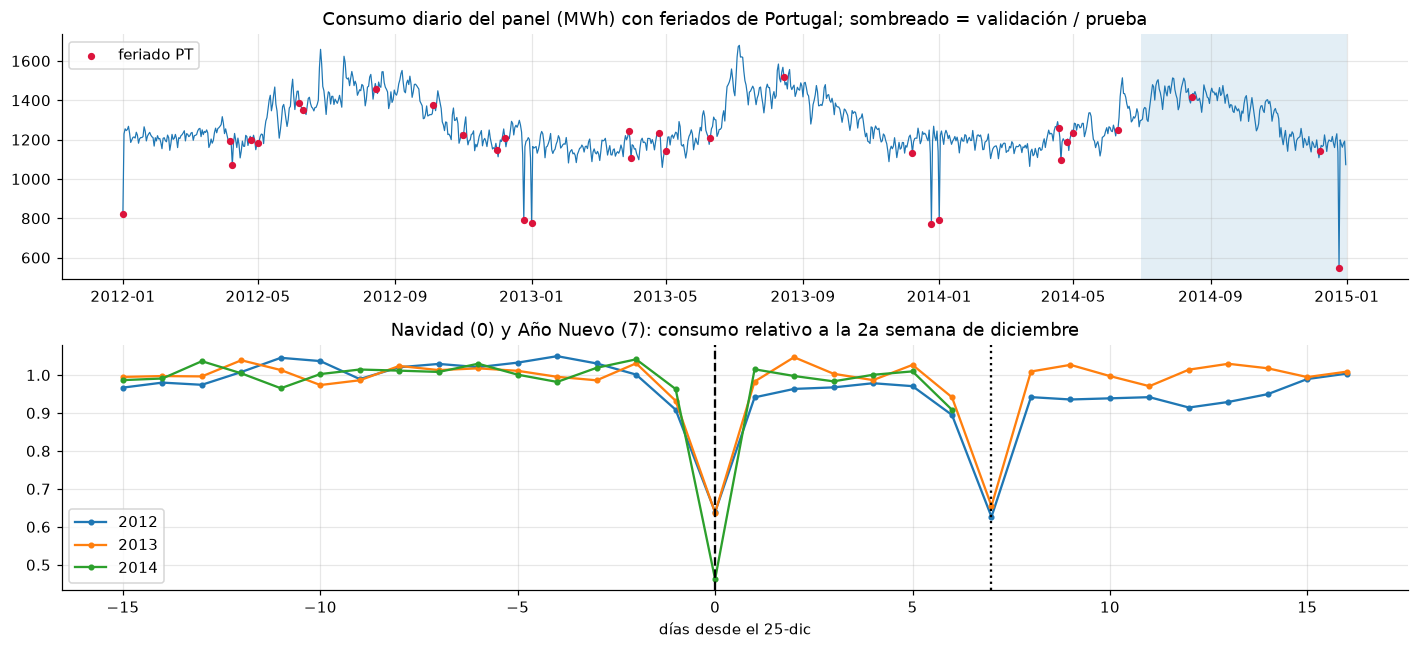

Cambio el 25-dic vs. 2a semana de dic: {2012: '-36.1%', 2013: '-36.3%', 2014: '-53.8%'}
Cambio el 01-ene vs. 2a semana de dic: {2012: '-37.4%', 2013: '-34.5%'}


In [8]:
daily = panel.sum(axis=1).resample("D").sum() / 1e3
hdays = [pd.Timestamp(d) for d in hol if pd.Timestamp("2012-01-01") <= pd.Timestamp(d) <= pd.Timestamp("2014-12-31")]
fig, ax = plt.subplots(2, 1, figsize=(13, 6))
ax[0].plot(daily.index, daily, lw=.8)
ax[0].scatter(hdays, daily.loc[hdays], color="crimson", s=14, zorder=3, label="feriado PT")
for a, b in ((C.VAL_START, C.VAL_END), (C.TEST_START, C.TEST_END)):
    ax[0].axvspan(pd.Timestamp(a), pd.Timestamp(b), alpha=.12)
ax[0].set(title="Consumo diario del panel (MWh) con feriados de Portugal; sombreado = validación / prueba"); ax[0].legend()
for y in (2012, 2013, 2014):
    w = daily.loc[f"{y}-12-10":f"{y+1}-01-10"] if y < 2014 else daily.loc[f"{y}-12-10":f"{y}-12-31"]
    ax[1].plot((w.index - pd.Timestamp(f"{y}-12-25")).days, w / w.iloc[:7].mean(), marker=".", label=str(y))
ax[1].axvline(0, color="k", ls="--"); ax[1].axvline(7, color="k", ls=":")
ax[1].set(title="Navidad (0) y Año Nuevo (7): consumo relativo a la 2a semana de diciembre", xlabel="días desde el 25-dic"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "holidays.png", bbox_inches="tight"); plt.show()
xm = {y: (daily.loc[f"{y}-12-25"] / daily.loc[f"{y}-12-10":f"{y}-12-16"].mean() - 1) for y in (2012, 2013, 2014)}
ny = {y: (daily.loc[f"{y+1}-01-01"] / daily.loc[f"{y}-12-10":f"{y}-12-16"].mean() - 1) for y in (2012, 2013)}
print("Cambio el 25-dic vs. 2a semana de dic:", {k: f"{v:+.1%}" for k, v in xm.items()})
print("Cambio el 01-ene vs. 2a semana de dic:", {k: f"{v:+.1%}" for k, v in ny.items()})

**Lectura.** Doble estacionalidad marcada: diaria (valle 2–6 h, meseta 9–19 h y pico
nocturno de iluminación) y semanal (sábado y sobre todo domingo más bajos). Los feriados se
comportan como domingos. En **Navidad y Año Nuevo** el consumo cae con fuerza (ver cifras)
y la semana entre ambos queda por debajo de lo normal: es un cambio de régimen corto que un
seasonal naive de 168 h no puede anticipar (copia la semana previa, que fue normal).

Consumo promedio por cliente (kWh/h, entrenamiento):
min       20.86
50%      159.50
max    11479.64
razón max/min = 550x


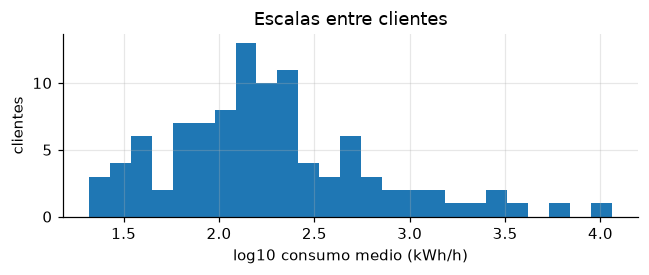

In [9]:
mean_c = panel.loc[:C.TRAIN_END].mean()
print("Consumo promedio por cliente (kWh/h, entrenamiento):")
print(mean_c.describe()[["min", "50%", "max"]].round(2).to_string())
print(f"razón max/min = {mean_c.max()/mean_c.min():.0f}x")
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(np.log10(mean_c), bins=25); ax.set(xlabel="log10 consumo medio (kWh/h)", ylabel="clientes", title="Escalas entre clientes")
plt.tight_layout(); plt.savefig(FIG / "scales.png", bbox_inches="tight"); plt.show()

**Normalización.** Las escalas difieren en ~3 órdenes de magnitud. Con una normalización
**global** la pérdida la dominan los 2–3 clientes grandes y los pequeños quedan en ≈0
(se verifica en la iteración de normalización). Elegimos **z-score por serie con media y
desviación del bloque de entrenamiento**: pone a todos los clientes en la misma escala para
un modelo global, es invertible para reportar en kWh y no usa información del futuro. Como
alternativa se probó la normalización **por ventana** (RevIN sin parámetros), que además
corrige cambios de nivel; PatchTST y los modelos de NeuralForecast la usan internamente.

### 2.1 Covariables de calendario conocidas a futuro

Hora (24), día de semana (7) y mes (12) se codifican con **seno/coseno**: dos columnas
continuas por variable que preservan la circularidad (23 h está junto a 0 h, diciembre junto
a enero) sin las 43 columnas de un one-hot. *Feriado* (librería `holidays`, Portugal) y
*fin de semana* son banderas binarias. Solo dependen del timestamp, por lo que se conocen
para cualquier hora futura en el instante del pronóstico.

In [10]:
show(D.calendar_features)
cal = D.calendar_features(idx)
cal.loc["2014-12-24 22:00":"2014-12-25 02:00"].round(3)

def calendar_features(index):
    """Codificación seno/coseno de hora (24), día de semana (7) y mes (12) + bandera
    de feriado de Portugal. Todas dependen solo del timestamp, por lo que se conocen
    en el instante de emitir el pronóstico para cualquier hora futura."""
    idx = pd.DatetimeIndex(index)
    hol = pt_holidays()
    f = pd.DataFrame(index=idx)
    for name, val, period in (("hour", idx.hour, 24), ("dow", idx.dayofweek, 7),
                              ("month", idx.month - 1, 12)):
        f[f"{name}_sin"] = np.sin(2 * np.pi * val / period)
        f[f"{name}_cos"] = np.cos(2 * np.pi * val / period)
    f["holiday"] = np.array([d in hol for d in idx.date], dtype="float32")
    f["weekend"] = (idx.dayofweek >= 5).astype("float32")
    return f.astype("float32")

,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,holiday,weekend
ds,,,,,,,,
2014-12-24 22:00:00,-0.500,0.866,0.975,-0.223,-0.5,0.866,0.0,0.0
2014-12-24 23:00:00,-0.259,0.966,0.975,-0.223,-0.5,0.866,0.0,0.0
2014-12-25 00:00:00,0.000,1.000,0.434,-0.901,-0.5,0.866,1.0,0.0
2014-12-25 01:00:00,0.259,0.966,0.434,-0.901,-0.5,0.866,1.0,0.0
2014-12-25 02:00:00,0.500,0.866,0.434,-0.901,-0.5,0.866,1.0,0.0


### 2.2 Dataset de ventanas deslizantes (PyTorch)

`WindowDataset` recorre todas las series y todos los orígenes válidos con stride 1 y
devuelve `X: (L, 1+8)` (consumo normalizado + calendario del pasado), `X_fut: (H, 8)`
(calendario del horizonte) y `y: (H,)`. Los orígenes de cada bloque se restringen para que
el **objetivo completo** caiga dentro del bloque; la entrada puede venir del bloque anterior
(es pasado observado en ese instante).

In [11]:
show(D.WindowDataset)
scaler = D.SeriesScaler().fit(Y[:P.t_train_end + 1])            # solo entrenamiento
Z, calv = scaler.transform(Y), cal.to_numpy()
ds_tr = D.WindowDataset(Z, calv, 0, P.t_train_end)
ds_va = D.WindowDataset(Z, calv, P.t_val, P.t_val_end)
ds_te = D.WindowDataset(Z, calv, P.t_test, P.t_test_end)
for n, d in (("entrenamiento", ds_tr), ("validación", ds_va), ("prueba", ds_te)):
    print(f"{n:14s}: {len(d.origins):6,} orígenes x {len(d.series)} series = {len(d):,} ventanas")
loader = torch.utils.data.DataLoader(ds_tr, batch_size=32, shuffle=True)
X, Xf, yb, ib = next(iter(loader))
print("X", tuple(X.shape), "| X_fut", tuple(Xf.shape), "| y", tuple(yb.shape))

class WindowDataset(Dataset):
    """Ventanas deslizantes sobre TODAS las series.

    Para cada serie i y cada origen t (primera hora a pronosticar):
      X      = [y_norm, calendario][t-L : t]       -> (L, 1 + N_CAL)
      X_fut  = calendario[t : t+H]                 -> (H, N_CAL)   (conocido a futuro)
      y      = y_norm[t : t+H]                     -> (H,)
    Los orígenes válidos se limitan a [t_lo, t_hi] de modo que el OBJETIVO completo
    caiga dentro del bloque (train/val/test) y la entrada solo use el pasado.
    """

    def __init__(self, values_norm, cal, t_lo, t_hi, L=C.L, H=C.H, stride=1,
                 series=None):
        self.v = torch.as_tensor(values_norm, dtype=torch.float32)   # (T, N)
        self.cal = torch.as_tensor(cal, dtype=torch.float32)         # (T, N_CAL)
        self.L, self.H = L, H
        t_lo = max(t_lo, L)                                          # se necesita historia L
        self.origins = np.arange(t_lo, t_hi - H + 2, stride)
        self.series = np.arange(self.v.shape[1]) if series is None else np.asarray(series)

    def __len__(self):
        return len(self.origins) * len(self.series)

    def __getitem__(self, k):
        i = self.series[k % len(self.series)]
        t = int(self.origins[k // len(self.series)])
        y_in = self.v[t - self.L:t, i].unsqueeze(-1)
        X = torch.cat([y_in, self.cal[t - self.L:t]], dim=-1)
        return X, self.cal[t:t + self.H], self.v[t:t + self.H, i], i

entrenamiento : 21,697 orígenes x 100 series = 2,169,700 ventanas
validación    :  2,185 orígenes x 100 series = 218,500 ventanas
prueba        :  2,185 orígenes x 100 series = 218,500 ventanas
X (32, 168, 9) | X_fut (32, 24, 8) | y (32, 24)


Para el backtest se usan además los **92 orígenes diarios** (00:00) de validación y de
prueba (`daily_origins`), que son el subconjunto de estas ventanas con stride 24.

### 2.3 Auditoría de fugas

Regla: cada entrada de la red debe poder calcularse en el instante en que se emite el
pronóstico (00:00 del día *d*, con datos hasta las 23:00 del día *d−1*).

In [12]:
# (1) Split aleatorio de ventanas -> NO: los bloques son cronológicos y disjuntos en el OBJETIVO.
last_tr_target = idx[ds_tr.origins.max() + C.H - 1]
first_va_target, last_va_target = idx[ds_va.origins.min()], idx[ds_va.origins.max() + C.H - 1]
first_te_target = idx[ds_te.origins.min()]
print("último objetivo de train:", last_tr_target, "| primer objetivo de val:", first_va_target)
print("último objetivo de val:  ", last_va_target, "| primer objetivo de test:", first_te_target)
assert last_tr_target < first_va_target and last_va_target < first_te_target
# El barajado (shuffle) ocurre SOLO dentro de los orígenes de entrenamiento:
src = inspect.getsource(train_model)
print([l.strip() for l in src.splitlines() if "tr_origins = " in l or "rng.choice(tr_origins" in l])

último objetivo de train: 2014-06-30 23:00:00 | primer objetivo de val: 2014-07-01 00:00:00
último objetivo de val:   2014-09-30 23:00:00 | primer objetivo de test: 2014-10-01 00:00:00
['tr_origins = np.arange(t_start + L, t_end - H + 2)', 't0s = rng.choice(tr_origins, cfg.batch)']


In [13]:
# (2) Escalar con toda la serie -> NO: mu/sd se ajustan solo con el bloque de entrenamiento.
sc_full = D.SeriesScaler().fit(Y)                       # lo que NO hacemos
print("diferencia media(train) vs media(serie completa), mediana entre clientes:",
      f"{np.median(np.abs(scaler.mu - sc_full.mu) / scaler.sd):.3f} desv.")
assert np.allclose(scaler.mu, Y[:P.t_train_end + 1].mean(0))
print([l.strip() for l in src.splitlines() if "Normalizer(cfg.norm" in l])

diferencia media(train) vs media(serie completa), mediana entre clientes: 0.024 desv.
['normalizer = Normalizer(cfg.norm, P.Y[t_start:t_end + 1])']


In [14]:
# (3) Early stopping con la prueba -> NO: el criterio es el MASE de los 92 orígenes de VALIDACIÓN.
print("orígenes de validación:", idx[P.val_origins[0]], "->", idx[P.val_origins[-1]])
print("el último horizonte de validación termina en", idx[P.val_origins[-1] + C.H - 1], "<", idx[P.t_test])
assert P.val_origins.max() + C.H - 1 < P.t_test
print([l.strip() for l in src.splitlines() if "val_origins = " in l or "best_state, wait = val_mase" in l])

orígenes de validación: 2014-07-01 00:00:00 -> 2014-09-30 00:00:00
el último horizonte de validación termina en 2014-09-30 23:00:00 < 2014-10-01 00:00:00
['val_origins = np.arange(v_lo, v_hi - H + 2, 24)', 'best, best_state, wait = val_mase, copy.deepcopy(net.state_dict()), 0']


In [15]:
# (4) Covariables mal alineadas -> NO: X termina a las 23:00 del día anterior, X_fut empieza a las 00:00
# del día pronosticado y solo contiene calendario (función del timestamp).
t0 = P.test_origins[84]                                   # 2014-12-24
print("entrada X:", idx[t0 - C.L], "->", idx[t0 - 1], "| calendario futuro:", idx[t0], "->", idx[t0 + C.H - 1])
x, xf, yy, _ = ds_te[list(ds_te.origins).index(t0) * len(ds_te.series)]
assert np.allclose(xf.numpy(), cal.iloc[t0:t0 + C.H].to_numpy())
print("feriado en X_fut (25-dic al día siguiente):", cal.iloc[t0 + 24:t0 + 26]["holiday"].tolist(), "| en X_fut[0] (24-dic):", xf[0, -2].item())

entrada X: 2014-12-17 00:00:00 -> 2014-12-23 23:00:00 | calendario futuro: 2014-12-24 00:00:00 -> 2014-12-24 23:00:00
feriado en X_fut (25-dic al día siguiente): [1.0, 1.0] | en X_fut[0] (24-dic): 0.0


In [16]:
# Prueba empírica para TODOS los forecasters: si se alteran los valores futuros (>= t0),
# el pronóstico emitido en t0 no cambia. backtest() solo entrega Y[:t0] al modelo.
show(backtest)

def backtest(model, Y, origins, H=C.H, scale=None):
    """Ejecuta el backtest de `model` sobre `origins`.

    En cada origen t0 el modelo solo ve Y[:t0] (datos hasta las 23:00 del día
    anterior) y pronostica Y[t0:t0+H]. Devuelve dict con F (N, O, H), A, quantiles
    opcionales y el tiempo de inferencia total.
    """
    F, Q = [], []
    tic = time.perf_counter()
    for t0 in origins:
        hist = Y[:t0]                                    # corte duro: nada del futuro
        F.append(model.forecast(hist, t0))
        if getattr(model, "quantiles", None) is not None:
            Q.append(model.forecast_quantiles(hist, t0))
    infer_time = time.perf_counter() - tic
    F = np.stack(F, axis=1).astype("float64")            # (N, O, H)
    A = np.stack([Y[t0:t0 + H].T for t0 in origins], axis=1).astype("float64")
    out = dict(name=model.name, F=F, A=A, origins=np.asarray(origins),
               infer_time=infer_time)
    if Q:
        out["Q"] = np.stack(Q, axis=1)                   # (N, O, H, nq)
        out["quantiles"] = model.quantiles
    if scale is not None:
        out["metrics"] = metrics(F, A, scale, out.get("Q"), out.get("quantiles"))
    return out

## 3. Investigación: herramientas para forecasting en PyTorch

**`nn.LSTM` / `nn.GRU`** — redes recurrentes con compuertas. `input_size`: features por paso;
`hidden_size`: dimensión del estado; `num_layers`: capas apiladas; `batch_first=True` usa
entradas `(B, L, F)`; `dropout`: entre capas (solo si `num_layers>1`). Salidas:
`output (B, L, hidden)` = estado oculto de la última capa en cada paso; `h_n (layers, B, hidden)`
= último estado de cada capa; `c_n` (solo LSTM) = última celda de memoria. La GRU no tiene
`c_n` (fusiona celda y estado) y tiene ~25 % menos parámetros.

**`nn.Conv1d` con `dilation` y padding causal** — `Conv1d(in, out, kernel_size, dilation=d)`;
para que la salida en *t* no vea *t+1…*, se rellena **solo a la izquierda** con
`(k−1)·d` ceros (o `padding=(k−1)·d` y se recortan los últimos elementos). Una TCN apila
bloques con dilataciones 1, 2, 4, …; el campo receptivo es
`R = 1 + Σ_b (k−1)·d_b` (× 2 si cada bloque residual tiene dos convoluciones). Con k=2 y
d = 1…128 (nuestra TCN): R = 1 + 255 = 256 h > L = 168.

**`nn.TransformerEncoderLayer`** — `d_model`: dimensión de los tokens, `nhead`: cabezas de
atención (d_model divisible por nhead), `dim_feedforward`: ancho del MLP interno,
`batch_first`, `dropout`. La atención es invariante a permutaciones, así que se **suma** una
codificación posicional (senoidal fija o embedding aprendido `nn.Embedding(L, d_model)`) al
embedding de entrada antes del encoder. PatchTST tokeniza parches de 24 h (canal
independiente); iTransformer usa cada **serie completa** como token y aplica la atención
entre variables.

**NeuralForecast / StatsForecast (Nixtla)** — entrada en formato largo
`(unique_id, ds, y)` más columnas exógenas. `cross_validation(df, h, n_windows, step_size,
refit)` hace backtesting con origen móvil: `n_windows` cortes, separados `step_size` pasos
(nosotros 92 y 24); `refit=False` entrena una sola vez (con el primer corte) y solo predice
en los siguientes, `refit=True`/entero reentrena en cada/cada *k* ventanas. En NeuralForecast
`val_size` reserva el final del entrenamiento para early stopping.

**Chronos-Bolt `BaseChronosPipeline.predict_quantiles`** — `inputs`: tensor `(B, T)` o lista
de tensores 1-D con el contexto (hasta 2048 pasos en Bolt); `prediction_length`: horizonte
(Bolt predice 64 pasos de una vez, más allá rueda autorregresivamente); `quantile_levels`:
lista de cuantiles (Bolt fue entrenado con 0.1…0.9). Devuelve `(quantiles (B, H, Q), mean (B, H))`.

**Modelo local vs. global** — local: un modelo por serie (solo ve su historia; no comparte
patrones, costo × N). Global: un modelo con todas las series (más datos, transfiere
patrones comunes, requiere normalización por serie).

**Teacher forcing** — al entrenar un modelo autorregresivo/seq2seq se alimenta el valor
**real** anterior en vez de la predicción. Acelera y estabiliza el entrenamiento, pero crea
*exposure bias*: en inferencia el modelo ve sus propios errores, que se acumulan con *h*.

**RevIN** — normaliza cada ventana de entrada con su media y desviación (más un afín
aprendible) y desnormaliza la salida con los mismos estadísticos. Ante cambios de nivel
(una serie que sube o baja de régimen) el modelo ve siempre entradas centradas y la
desnormalización traslada el nivel reciente al pronóstico.

**Pinball loss** — `ρ_q(y, ŷ) = max(q(y−ŷ), (q−1)(y−ŷ))`. Su minimizador es el cuantil *q*
de la distribución condicional; promediada sobre varios *q* aproxima el CRPS. La cobertura
P10–P90 debería ser ≈ 80 %.

**MASE vs WAPE** — ambas libres de escala. **MASE** = MAE / MAE in-sample del seasonal
naive (m = 24) **por serie** y luego se promedia: cada cliente pesa igual y < 1 significa
mejor que el naive estacional. **WAPE** = Σ|e| / Σ|y| sobre todo el panel: pondera por
volumen (los clientes grandes dominan) y se lee como % del consumo total.

## 4. Protocolo de validación y métricas

Una sola función `backtest(modelo)` para todos los modelos. En cada uno de los 92 orígenes
(00:00 de cada día de oct–dic 2014) el modelo recibe **solo `Y[:t0]`** y devuelve las 24
horas siguientes. Los pesos se entrenan una vez con datos hasta 2014-09-30 (entrenamiento +
validación para early stopping). Los modelos de librería se envuelven con la misma interfaz
`Forecaster.forecast(hist, t0)`.

In [17]:
show(Forecaster); show(metrics)

class Forecaster:
    """Interfaz común. `forecast(hist, t0)` recibe SOLO Y[:t0] (kWh, forma (t0, N)) y
    devuelve (N, H) — o (N, H, Q) en `forecast_quantiles` para modelos probabilísticos."""
    name = "base"
    quantiles = None

    def forecast(self, hist, t0):
        raise NotImplementedError

def metrics(F, A, scale, Q=None, qs=None, mask_origins=None):
    """Métricas en kWh agregadas sobre todos los clientes y orígenes."""
    if mask_origins is not None:
        F, A = F[:, mask_origins], A[:, mask_origins]
        Q = None if Q is None else Q[:, mask_origins]
    E = F - A
    mae_c = np.abs(E).mean(axis=(1, 2))
    rmse_c = np.sqrt((E ** 2).mean(axis=(1, 2)))
    nz = A > 0
    ape = np.abs(E[nz]) / A[nz]
    m = dict(
        MAE=float(np.abs(E).mean()),
        RMSE=float(np.sqrt((E ** 2).mean())),
        WAPE=float(np.abs(E).sum() / np.abs(A).sum()),
        MAPE=float(ape.mean()),                 # excluye y=0 (división indefinida)
        MAPE_p99=float(np.quantile(ape, 0.99)),
        MASE=float((mae_c / scale).mean()),
        MAE_by_client=mae_c, RMSE_by_client=rmse_c, MASE_by_client=mae_c / scale,
        MAE_by_h=np.abs(E).mean(axis=(0, 1)),
        MASE_by_h=(np.abs(E).mean(axis=1) / scale[:, None]).mean(axis=0),
    )
    if Q is not None:
        lo, hi = qs.index(0.1), qs.index(0.9)
        m["pinball"] = pinball(Q, A, qs)
        m["coverage_80"] = float(((A >= Q[..., lo]) & (A <= Q[..., hi])).mean())
    return m

In [18]:
# Ejemplo: seasonal naive en numpy pasado por backtest() y la prueba de "futuro alterado"
class SNaive(Forecaster):
    def __init__(self, m): self.m, self.name = m, f"SNaive{m}"
    def forecast(self, hist, t0): return hist[-self.m:][:C.H].T    # mismo día de hace m horas

def future_invariance(model, t0):
    Yp = Y.copy(); Yp[t0:] = Yp[t0:] * 3 + 1000           # alterar el futuro
    return np.allclose(model.forecast(Y[:t0], t0), model.forecast(Yp[:t0], t0))

sn = SNaive(168)
r = backtest(sn, Y, P.test_origins, scale=P.scale)
print({k: round(v, 4) for k, v in r["metrics"].items() if isinstance(v, float)})
print("invariante al futuro:", future_invariance(sn, P.test_origins[10]))

{'MAE': 39.7212, 'RMSE': 182.4477, 'WAPE': 0.0771, 'MAPE': 0.112, 'MAPE_p99': 0.83, 'MASE': 1.1137}
invariante al futuro: True


**MAPE y clientes de consumo cercano a cero.** El MAPE divide entre el valor real: con
horas en 0 kWh es indefinido (se excluyen) y con horas de 0.1–1 kWh un error pequeño en kWh
se vuelve un error de cientos o miles por ciento. Por eso el promedio lo dominan pocos
clientes y horas nocturnas; abajo se muestra la distribución del APE por cliente. Para
comparar modelos usamos MASE (por cliente) y WAPE (por volumen).

In [19]:
E = np.abs(r["F"] - r["A"]); A_ = r["A"]
ape_c = np.array([np.mean(E[i][A_[i] > 0] / A_[i][A_[i] > 0]) for i in range(P.N)])
low = np.argsort(P.Y[:P.t_train_end].mean(0))[:5]
print("MAPE por cliente (SNaive168): mediana", f"{np.median(ape_c):.1%}", "| máx", f"{ape_c.max():.0%}")
print("5 clientes de menor consumo:", {P.columns[i]: f"{ape_c[i]:.0%}" for i in low})
print("fracción de horas reales < 1 kWh en prueba:", f"{(A_ < 1).mean():.2%}")

MAPE por cliente (SNaive168): mediana 9.6% | máx 52%
5 clientes de menor consumo: {'MT_026': '11%', 'MT_063': '11%', 'MT_149': '6%', 'MT_022': '13%', 'MT_150': '7%'}
fracción de horas reales < 1 kWh en prueba: 0.63%


## 5. Construcción y entrenamiento de los modelos

### 5.0 Implementaciones propias (PyTorch)
Todas reciben `X (B, L, 1+8)` y `X_fut (B, H, 8)` y devuelven `(B, 24)` en escala normalizada.

In [20]:
for cls in (TM.MLP, TM.DLinear, TM.NLinear, TM.LSTMMimo, TM.LSTMAutoregressive, TM.LSTMSeq2Seq):
    show(cls)

class MLP(nn.Module):
    """MLP multi-salida: [ventana L de consumo, calendario futuro aplanado] -> 24 pasos."""
    strategy, uses_cov = "multi-salida", True

    def __init__(self, L, H, hidden=512, layers=2, dropout=0.1):
        super().__init__()
        dims, mods = L + H * N_CAL, []
        for _ in range(layers):
            mods += [nn.Linear(dims, hidden), nn.ReLU(), nn.Dropout(dropout)]
            dims = hidden
        self.net = nn.Sequential(*mods, nn.Linear(dims, H))

    def forward(self, X, Xf):
        return self.net(torch.cat([X[..., 0], Xf.flatten(1)], dim=1))

class DLinear(nn.Module):
    """DLinear (Zeng et al., 2023): y = W_t * tendencia + W_s * resto. Sin covariables."""
    strategy, uses_cov = "multi-salida", False

    def __init__(self, L, H, kernel=25):
        super().__init__()
        self.decomp = MovingAvg(kernel)
        self.lin_trend, self.lin_season = nn.Linear(L, H), nn.Linear(L, H)

    def forward(self, X, Xf):
        x = X[..., 0]
        trend = self.decomp(x)
        return self.lin_trend(trend) + self.lin_season(x - trend)

class NLinear(nn.Module):
    """NLinear: resta el último valor, capa lineal L->H, y lo vuelve a sumar."""
    strategy, uses_cov = "multi-salida", False

    def __init__(self, L, H):
        super().__init__()
        self.lin = nn.Linear(L, H)

    def forward(self, X, Xf):
        x = X[..., 0]
        last = x[:, -1:]
        return self.lin(x - last) + last

class LSTMMimo(nn.Module):
    """LSTM multi-salida: el último estado oculto + calendario futuro -> capa densa de 24."""
    strategy, uses_cov = "multi-salida", True

    def __init__(self, L, H, hidden=128, layers=2, dropout=0.1):
        super().__init__()
        self.rnn = nn.LSTM(1 + N_CAL, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden + H * N_CAL, hidden), nn.ReLU(),
                                  nn.Linear(hidden, H))

    def forward(self, X, Xf):
        _, (h_n, _) = self.rnn(X)                           # h_n: (layers, B, hidden)
        return self.head(torch.cat([h_n[-1], Xf.flatten(1)], dim=1))

class LSTMAutoregressive(nn.Module):
    """LSTM autorregresiva: entrada en t = [y_t, calendario_{t+1}] -> y_{t+1}.

    Entrenamiento con teacher forcing (se alimenta el valor real anterior en todas las
    posiciones); en inferencia se realimenta la propia predicción durante 24 pasos.
    """
    strategy, uses_cov = "autorregresiva", True

    def __init__(self, L, H, hidden=128, layers=2, dropout=0.1):
        super().__init__()
        self.H = H
        self.rnn = nn.LSTM(1 + N_CAL, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        self.out = nn.Linear(hidden, 1)

    def _inputs(self, y, cal_next):
        return torch.cat([y.unsqueeze(-1), cal_next], dim=-1)

    def forward(self, X, Xf, y_true=None):
        y_hist, cal_hist = X[..., 0], X[..., 1:]
        cal_next = torch.cat([cal_hist[:, 1:], Xf[:, :1]], dim=1)   # calendario de t+1
        if y_true is not None:                                      # teacher forcing
            y_all = torch.cat([y_hist, y_true[:, :-1]], dim=1)
            cal_all = torch.cat([cal_next, Xf[:, 1:]], dim=1)
            o, _ = self.rnn(self._inputs(y_all, cal_all))
            return self.out(o).squeeze(-1)[:, -self.H:]           # pérdida en los H pasos
        o, state = self.rnn(self._inputs(y_hist, cal_next))
        y_prev, preds = self.out(o[:, -1]).squeeze(-1), []
        preds.append(y_prev)
        for h in range(1, self.H):                                  # realimenta su predicción
            inp = self._inputs(y_prev.unsqueeze(1), Xf[:, h:h + 1])
            o, state = self.rnn(inp, state)
            y_prev = self.out(o[:, -1]).squeeze(-1)
            preds.append(y_prev)
        return torch.stack(preds, dim=1)

class LSTMSeq2Seq(nn.Module):
    """Encoder-decoder: el encoder LSTM resume la ventana; el decoder LSTM recibe en cada
    paso futuro el calendario conocido (hora, día, mes, feriado) y, opcionalmente, el
    valor anterior (teacher forcing con probabilidad `tf_ratio` durante entrenamiento)."""
    strategy, uses_cov = "encoder-decoder", True

    def __init__(self, L, H, hidden=128, layers=2, dropout=0.1, feed_prev=False,
                 tf_ratio=0.5):
        super().__init__()
        self.H, self.feed_prev, self.tf_ratio = H, feed_prev, tf_ratio
        self.enc = nn.LSTM(1 + N_CAL, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        self.dec = nn.LSTM(N_CAL + int(feed_prev), hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        self.out = nn.Linear(hidden, 1)

    def forward(self, X, Xf, y_true=None):
        _, state = self.enc(X)
        if not self.feed_prev:                         # decoder no autorregresivo
            o, _ = self.dec(Xf, state)
            return self.out(o).squeeze(-1)
        y_prev, preds = X[:, -1, 0], []
        for h in range(self.H):
            inp = torch.cat([y_prev[:, None, None], Xf[:, h:h + 1]], dim=-1)
            o, state = self.dec(inp, state)
            y_hat = self.out(o[:, -1]).squeeze(-1)
            preds.append(y_hat)
            use_tf = (y_true is not None and self.training
                      and torch.rand(()) < self.tf_ratio)
            y_prev = y_true[:, h] if use_tf else y_hat
        return torch.stack(preds, dim=1)

In [21]:
from src import train_torch as TT
show(TT.train_model)

def train_model(cfg: TrainConfig, panel: Panel, device=None, verbose=True,
                t_train_end=None, val_block=None):
    """Entrena con el bloque de entrenamiento (últimos `months` meses hasta 2014-06-30)
    y hace early stopping con el MASE de validación. Devuelve (forecaster, log).
    `t_train_end` y `val_block=(t_ini, t_fin)` permiten mover el corte (reentrenamiento
    mensual con ventana expandible)."""
    device = device or get_device()
    set_seed(cfg.seed)
    P, L, H = panel, cfg.L, cfg.H
    cols_all = np.arange(P.N) if cfg.series is None else np.asarray(cfg.series)
    t_end = P.t_train_end if t_train_end is None else t_train_end
    v_lo, v_hi = (P.t_val, P.t_val_end) if val_block is None else val_block
    t_start = max(0, t_end + 1 - cfg.months * 30 * 24 - L)  # +L de contexto inicial
    # El normalizador solo ve el bloque de entrenamiento (sin validación ni prueba).
    normalizer = Normalizer(cfg.norm, P.Y[t_start:t_end + 1])
    Zb = normalizer.base(P.Y, np.arange(P.N)).astype("float32")      # (T, N)
    # orígenes de entrenamiento: el objetivo completo debe caer en <= TRAIN_END
    tr_origins = np.arange(t_start + L, t_end - H + 2)

    net = MODELS[cfg.model](L, H, **_model_kwargs(cfg)).to(device)
    n_tot, n_tr = count_params(net)
    opt = torch.optim.AdamW(net.parameters(), lr=cfg.lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    crit = nn.L1Loss() if cfg.loss == "l1" else nn.MSELoss()
    rng = np.random.default_rng(cfg.seed)
    teacher = cfg.model in ("LSTM-AR",) or (cfg.model == "LSTM-Seq2Seq"
                                            and cfg.extra.get("feed_prev"))

    fc = TorchForecaster(cfg.model, net, cfg, P, normalizer, device)
    # validación: 92 orígenes diarios del bloque jul-sep (todas las series del modelo)
    # (con H > 24 se descartan orígenes cuyo horizonte invadiría el bloque de prueba)
    val_origins = np.arange(v_lo, v_hi - H + 2, 24)
    v_t0 = np.repeat(val_origins, len(cols_all))
    v_cols = np.tile(cols_all, len(val_origins))
    Xv, Xfv, yv, v_stats = _gather(Zb, P.cal, v_t0, v_cols, L, H, cfg.norm)
    A_val = np.stack([P.Y[t:t + H, cols_all].T for t in val_origins], axis=1)  # (n,O,H)

    best, best_state, wait, log = np.inf, None, 0, []
    if device.type == "mps":
        torch.mps.empty_cache()
    peak_mem = 0
    t_total = time.perf_counter()
    for ep in range(1, cfg.epochs + 1):
        net.train()
        tic, losses = time.perf_counter(), []
        n_batches = max(1, cfg.samples_per_epoch // cfg.batch)
        for _ in range(n_batches):
            t0s = rng.choice(tr_origins, cfg.batch)
            cols = rng.choice(cols_all, cfg.batch)
            X, Xf, y, _ = _gather(Zb, P.cal, t0s, cols, L, H, cfg.norm)
            X, Xf, y = (torch.as_tensor(a, device=device) for a in (X, Xf, y))
            pred = net(X, Xf, y) if teacher else net(X, Xf)
            loss = crit(pred, y)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            losses.append(loss.item())
            if device.type == "mps":                 # memoria de tensores vivos en GPU
                peak_mem = max(peak_mem, torch.mps.current_allocated_memory())
        if device.type == "mps":                     # libera la caché del allocator
            torch.mps.empty_cache()
        if device.type == "cuda":
            peak_mem = max(peak_mem, torch.cuda.max_memory_allocated())
        ep_time = time.perf_counter() - tic

        # ---- validación (sin gradientes) ----
        net.eval()
        with torch.no_grad():
            pv = []
            for k in range(0, len(Xv), 512):          # lotes chicos: la LSTM en MPS reserva mucha memoria
                pv.append(net(torch.as_tensor(Xv[k:k + 512], device=device),
                              torch.as_tensor(Xfv[k:k + 512], device=device)).cpu())
            pv = torch.

Los modelos de librería (StatsForecast, LightGBM, NeuralForecast y Chronos) se envuelven con la
misma interfaz `Forecaster` en `src/library_models.py`:

In [22]:
from src import library_models as LM
show(LM.LGBMForecaster); show(LM.NFForecaster.forecast); show(LM.ChronosForecaster)

class LGBMForecaster(Forecaster):
    """LightGBM global (un solo modelo para todos los clientes) con rezagos 1-24 y 168,
    calendario (hora, día, mes, feriado) e id del cliente como categórica. El objetivo se
    normaliza por serie (z-score de entrenamiento). Multi-paso recursivo: en el paso h
    los rezagos < h se llenan con las propias predicciones."""

    def __init__(self, P, months=30, params=None, seed=C.SEED, name="LightGBM",
                 rounds=2000):
        self.P, self.months, self.name, self.rounds = P, months, name, rounds
        self.params = dict(objective="l1", learning_rate=0.05, num_leaves=127,
                           min_data_in_leaf=100, feature_fraction=0.8, bagging_fraction=0.8,
                           bagging_freq=1, verbose=-1, seed=seed, num_threads=12)
        self.params.update(params or {})

    def _cal_int(self, t):
        idx = self.P.index[t]
        hol = self.P.cal[t, CAL_COLS.index("holiday")]
        return np.stack([idx.hour, idx.dayofweek, idx.month, hol], axis=-1)

    def _features(self, Z, t, cols):
        """Filas para (series `cols`, tiempo t) usando solo Z[t - lag]."""
        lags = np.stack([Z[t - l, cols] for l in LAGS], axis=-1)
        cal = np.repeat(self._cal_int(np.array([t]))[None], len(cols), axis=0).reshape(len(cols), -1)
        return np.concatenate([lags, cal, cols[:, None]], axis=1)

    def _matrix(self, Z, t_lo, t_hi):
        """Matriz de entrenamiento vectorizada para t in [t_lo, t_hi]."""
        ts = np.arange(t_lo, t_hi + 1)
        N = Z.shape[1]
        lag = np.stack([Z[ts - l] for l in LAGS], axis=-1)              # (T, N, nl)
        cal = np.repeat(self._cal_int(ts)[:, None], N, axis=1)          # (T, N, 4)
        sid = np.broadcast_to(np.arange(N)[None, :, None], (len(ts), N, 1))
        X = np.concatenate([lag, cal, sid], axis=-1).reshape(-1, len(LAGS) + 5)
        return X, Z[ts].reshape(-1)

    def fit(self, t_train_end=None, t_val=None):
        import lightgbm as lgb
        P = self.P
        t_train_end = P.t_train_end if t_train_end is None else t_train_end
        t_lo = max(168, t_train_end + 1 - self.months * 30 * 24)
        tr = P.Y[t_lo:t_train_end + 1]
        self.mu, self.sd = tr.mean(0), tr.std(0) + 1e-6       # stats solo de entrenamiento
        Z = (P.Y - self.mu) / self.sd
        names = [f"lag{l}" for l in LAGS] + ["hour", "dow", "month", "holiday", "client"]
        Xtr, ytr = self._matrix(Z, t_lo, t_train_end)
        dtr = lgb.Dataset(Xtr, ytr, feature_name=names, categorical_feature=["client"])
        valid, cb = [], []
        if t_val is not None:                                   # early stopping en validación
            Xv, yv = self._matrix(Z, t_val[0], t_val[1])
            valid = [lgb.Dataset(Xv, yv, reference=dtr)]
            cb = [lgb.early_stopping(50, verbose=False)]
        tic = time.perf_counter()
        self.booster = lgb.train(self.params, dtr, num_boost_round=self.rounds,
                                 valid_sets=valid, callbacks=cb)
        self.train_time = time.perf_counter() - tic
        self.n_params = self.booster.num_trees()
        return self

    def forecast(self, hist, t0, H=C.H):
        N = hist.shape[1]
        cols = np.arange(N)
        Zh = (hist[-200:] - self.mu) / self.sd                     # solo el pasado
        buf = np.concatenate([Zh, np.zeros((H, N))], axis=0)
        base = len(Zh)
        for h in range(H):
            t = base + h
            lags = np.stack([buf[t - l] for l in LAGS], axis=-1)
            cal = np.repeat(self._cal_int(np.array([t0 + h])), N, axis=0)
            X = np.concatenate([lags, cal, cols[:, None]], axis=1)
            buf[t] = self.booster.predict(X, num_threads=12)
        return (buf[base:] * self.sd + self.mu).T

def forecast(self, hist, t0):
        pred = self._predict(hist, t0)
        q = self._qcols(pred)
        col = q[0.5] if 0.5 in q else self.name      # probabilísticos: la mediana
        return self._pivot(pred, col)

class ChronosForecaster(Forecaster):
    """Chronos-Bolt sin entrenamiento: contexto = últimas `ctx` horas de cada cliente."""

    def __init__(self, model_id="amazon/chronos-bolt-base", ctx=2048, device=None,
                 quantiles=C.QUANTILES, name="Chronos-Bolt", batch=25):
        from chronos import BaseChronosPipeline
        dev = device or ("mps" if torch.backends.mps.is_available() else "cpu")
        self.pipe = BaseChronosPipeline.from_pretrained(model_id, device_map=dev,
                                                        torch_dtype=torch.float32)
        self.ctx, self.quantiles, self.qlev, self.name = ctx, quantiles, list(quantiles), name
        self.batch = batch
        self.n_params = sum(p.numel() for p in self.pipe.model.parameters())
        self._last = None

    def _run(self, hist, t0, H=C.H):
        if self._last is not None and self._last[0] == t0 and self._last[1] == H:
            return self._last[2]
        ctx = torch.as_tensor(hist[-self.ctx:].T.copy(), dtype=torch.float32)
        qs, ms = [], []
        for k in range(0, len(ctx), self.batch):          # lotes acotan la memoria (MPS)
            q, mean = self.pipe.predict_quantiles(ctx[k:k + self.batch], prediction_length=H,
                                                  quantile_levels=self.qlev)
            qs.append(q.cpu().numpy()); ms.append(mean.cpu().numpy())
        self._last = (t0, H, (np.concatenate(qs), np.concatenate(ms)))
        return self._last[2]

    def forecast(self, hist, t0):
        q, _ = self._run(hist, t0)
        return q[..., self.qlev.index(0.5)]                      # mediana como punto

    def forecast_quantiles(self, hist, t0):
        return self._run(hist, t0)[0]

### 5.1 Estrategias multi-paso con la LSTM

In [23]:
it = pd.read_csv(ITER_CSV); ep = pd.read_csv(EPOCH_CSV)
strat = it[(it.group == "long") & it.model.str.startswith("LSTM")].copy()   # mismo presupuesto (40 épocas)
strat["estrategia"] = strat.apply(lambda r: {"LSTM-AR": "autorregresiva", "LSTM-MIMO": "multi-salida",
    "LSTM-Seq2Seq": "encoder-decoder" + (" (realimenta y, TF 0.5)" if "_fp" in r.tag else "")}[r.model], axis=1)
display(strat[["estrategia", "best_val_MASE", "params_total", "epochs_run", "train_time"]].round(4))

,estrategia,best_val_MASE,params_total,epochs_run,train_time
31,autorregresiva,1.0036,203393,40.0,196.8605
32,multi-salida,0.9968,247448,40.0,177.9843
33,encoder-decoder,0.9706,406145,40.0,203.9465
34,"encoder-decoder (realimenta y, TF 0.5)",1.0221,406657,40.0,218.4471


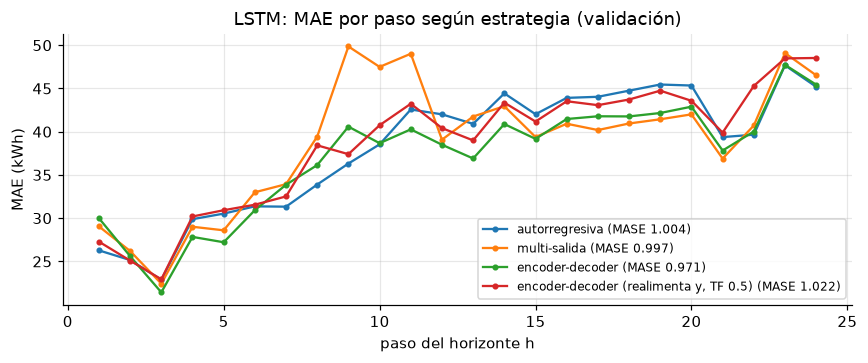

In [24]:
# MAE por paso del horizonte de cada estrategia (en VALIDACIÓN: la prueba se usa una vez por modelo)
from importlib import import_module
tm04 = import_module("src.04_torch_models") if False else None
import importlib.util
spec = importlib.util.spec_from_file_location("s04", ROOT / "src" / "04_torch_models.py")
s04 = importlib.util.module_from_spec(spec); spec.loader.exec_module(s04)
device = get_device()
fig, ax = plt.subplots(figsize=(8, 3.4))
for _, row in strat.iterrows():
    fc, cfg = s04.load_forecaster(row, P, device, row.estrategia)
    rv = backtest(fc, Y, P.val_origins, scale=P.scale)
    ax.plot(range(1, 25), rv["metrics"]["MAE_by_h"], marker=".", label=f"{row.estrategia} (MASE {rv['metrics']['MASE']:.3f})")
ax.set(xlabel="paso del horizonte h", ylabel="MAE (kWh)", title="LSTM: MAE por paso según estrategia (validación)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "strategies.png", bbox_inches="tight"); plt.show()

### 5.2 Iteraciones de hiperparámetros (solo validación)

In [25]:
cols = ["group", "model", "L", "H", "months", "norm", "hidden", "layers", "dropout", "lr", "batch",
        "params_total", "params_trainable", "best_epoch", "epochs_run", "best_val_MASE",
        "epoch_time_mean", "train_time", "peak_mem_MB"]
pd.set_option("display.max_rows", 80)
it[[c for c in cols if c in it]].round(4)

,group,model,L,H,months,norm,hidden,layers,dropout,lr,batch,params_total,params_trainable,best_epoch,epochs_run,best_val_MASE,epoch_time_mean,train_time,peak_mem_MB
0,window_L,DLinear,48,24,30,series,128.0,2.0,0.1,0.0010,512.0,2352,2352,25.0,25.0,0.9581,0.1466,3.7740,1.3591
1,window_L,DLinear,168,24,30,series,128.0,2.0,0.1,0.0010,512.0,8112,8112,22.0,25.0,0.8830,0.2236,5.7579,3.6438
2,window_L,DLinear,336,24,30,series,128.0,2.0,0.1,0.0010,512.0,16176,16176,25.0,25.0,0.8623,0.4186,10.9739,6.8416
3,window_L,LSTM-Seq2Seq,48,24,30,series,128.0,2.0,0.1,0.0010,512.0,406145,406145,25.0,25.0,1.0345,1.7346,47.6338,9.1846
4,window_L,LSTM-Seq2Seq,168,24,30,series,128.0,2.0,0.1,0.0010,512.0,406145,406145,25.0,25.0,1.0141,12.4778,948.5828,14.3159
5,window_L,LSTM-Seq2Seq,336,24,30,series,128.0,2.0,0.1,0.0010,512.0,406145,406145,15.0,15.0,1.0767,80.8167,1343.2550,0.0000
6,history,DLinear,168,24,3,series,128.0,2.0,0.1,0.0010,512.0,8112,8112,13.0,15.0,0.8866,0.1861,3.1087,3.6252
7,history,DLinear,168,24,12,series,128.0,2.0,0.1,0.0010,512.0,8112,8112,15.0,15.0,0.8911,0.1965,3.2960,3.6252
8,history,LSTM-Seq2Seq,168,24,3,series,128.0,2.0,0.1,0.0010,512.0,406145,406145,8.0,11.0,1.2635,4.3354,52.8434,11.2168
9,history,LSTM-Seq2Seq,168,24,12,series,128.0,2.0,0.1,0.0010,512.0,406145,406145,13.0,15.0,1.0879,4.5166,74.9919,11.2168


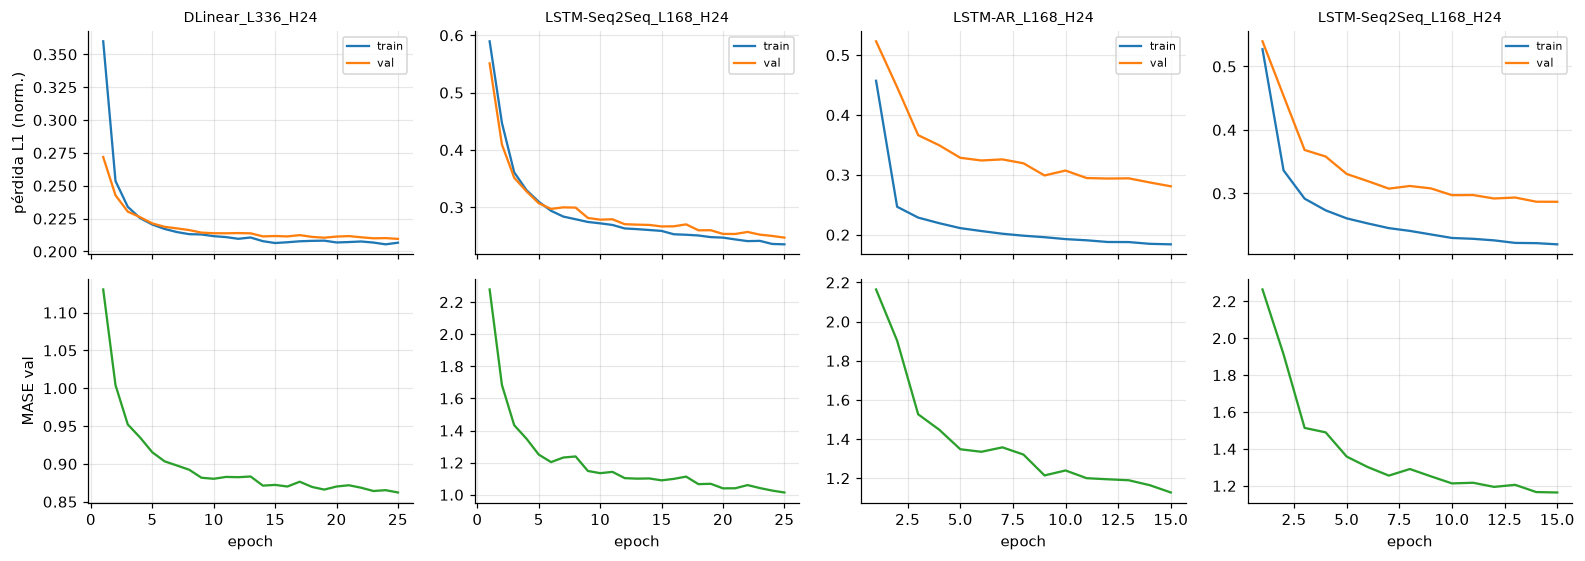

In [26]:
# Curvas de pérdida (train vs. validación) y MASE de validación por epoch
sel = [t for t in it.tag if t.startswith(("DLinear_L336_H24_m30_series", "LSTM-Seq2Seq_L168_H24_m30_series_h128_l2_d0.1_lr0.001_b512",
                                           "MLP_L168_H24_m30_series_h128_l2_d0.1_lr0.001_b512", "LSTM-AR_L168"))][:4]
fig, ax = plt.subplots(2, len(sel), figsize=(3.6 * len(sel), 5.2), sharex="col")
for j, t in enumerate(sel):
    e = ep[ep.tag == t]
    ax[0, j].plot(e.epoch, e.train_loss, label="train"); ax[0, j].plot(e.epoch, e.val_loss, label="val")
    ax[0, j].set_title(t.split("_m30")[0], fontsize=9); ax[0, j].legend(fontsize=7)
    ax[1, j].plot(e.epoch, e.val_MASE, color="C2"); ax[1, j].set_xlabel("epoch")
ax[0, 0].set_ylabel("pérdida L1 (norm.)"); ax[1, 0].set_ylabel("MASE val")
plt.tight_layout(); plt.savefig(FIG / "loss_curves.png", bbox_inches="tight"); plt.show()

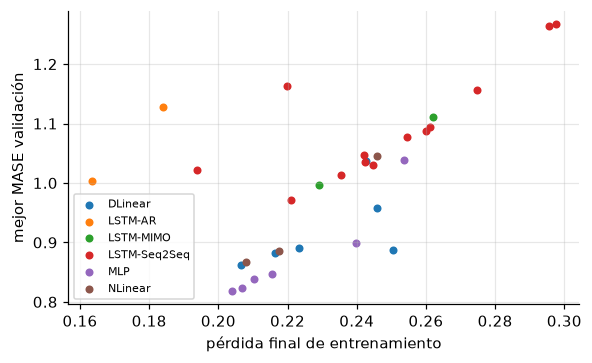

correlación de Spearman: 0.646


In [27]:
# ¿Menor pérdida de entrenamiento => mejor MASE de validación?
last = ep.groupby("tag").agg(train_loss=("train_loss", "last"), val_MASE=("val_MASE", "min")).join(it.set_index("tag")[["model", "norm"]])
last = last[last.norm == "series"]
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for m, g in last.groupby("model"):
    ax.scatter(g.train_loss, g.val_MASE, label=m, s=18)
ax.set(xlabel="pérdida final de entrenamiento", ylabel="mejor MASE validación"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("correlación de Spearman:", round(last[["train_loss", "val_MASE"]].corr("spearman").iloc[0, 1], 3))

### 5.3 Modelo local contra global

In [28]:
lg = pd.read_csv(C.RESULTS_DIR / "local_vs_global.csv")
best_name = load_run(pd.read_csv(C.RESULTS_DIR / "seeds.csv").model.iloc[0]).get("name")
g = load_run(best_name)
mae_c = np.abs(g["F"] - g["A"]).mean(axis=(1, 2))
lg["global_MASE"] = mae_c[lg.idx] / P.scale[lg.idx]
lg["mejora_global"] = 1 - lg.global_MASE / lg.local_MASE
display(lg[["client", "mean_kwh", "local_MASE", "global_MASE", "mejora_global"]].round(3))
print("MASE promedio 10 clientes  local:", round(lg.local_MASE.mean(), 4), "| global:", round(lg.global_MASE.mean(), 4))

,client,mean_kwh,local_MASE,global_MASE,mejora_global
0,MT_046,131.094,0.840,0.838,0.002
1,MT_050,164.505,0.721,0.721,-0.001
2,MT_083,71.758,0.721,0.731,-0.014
3,MT_174,148.193,1.211,1.138,0.060
4,MT_247,466.957,0.740,0.649,0.123
5,MT_268,238.072,1.004,0.868,0.135
6,MT_279,11479.638,0.987,0.990,-0.004
7,MT_319,94.970,1.022,0.911,0.109
8,MT_357,1874.228,0.955,0.926,0.030
9,MT_360,512.045,0.915,0.806,0.120


MASE promedio 10 clientes  local: 0.9114 | global: 0.8578


## 6. Comparación de resultados (prueba, 92 orígenes)

In [29]:
runs = list_runs("test")
rows = []
for n in runs:
    r = load_run(n); m = r["meta"]
    row = summary_row(r, P.scale, idx)
    row.update(family=m.get("family"), L=m.get("L"), strategy=m.get("strategy"), covariates=m.get("covariates"),
               params_total=m.get("params_total"), params_trainable=m.get("params_trainable"),
               train_s=m.get("train_time"), hardware=m.get("hardware"))
    rows.append(row)
h168 = {}
for n in list_runs("test168"):
    r = load_run(n, "test168"); h168[n.replace("_H168", "")] = metrics(r["F"], r["A"], P.scale)["MASE"]
table = pd.DataFrame(rows)
table["MASE_H168"] = table.model.map(h168)
table = table.sort_values("MASE").reset_index(drop=True)
order = ["model", "family", "L", "strategy", "covariates", "params_total", "params_trainable", "train_s", "infer_s",
         "MAE", "RMSE", "WAPE", "MAPE", "MASE", "MASE_H168", "MASE_xmas", "pinball", "coverage_80", "hardware"]
table = table[[c for c in order if c in table]]
table.to_csv(C.RESULTS_DIR / "comparison_table.csv", index=False)
table.round(4)

,model,family,L,strategy,covariates,params_total,params_trainable,train_s,infer_s,MAE,RMSE,WAPE,MAPE,MASE,MASE_H168,MASE_xmas,pinball,coverage_80,hardware
0,Chronos-Bolt,Fundacional,2048,multi-salida (cuantiles),No,205292928,0,0.0000,65.8522,30.4473,201.2292,0.0591,0.0770,0.7374,0.9166,1.3362,10.5833,0.7983,"Apple M4 Pro (MPS), arm64"
1,iTransformer,Atención,168,multi-salida,No,1104152,1104152,506.5328,1.1047,33.1042,162.1609,0.0642,0.0880,0.8028,NaN,1.2784,NaN,NaN,"Apple M4 Pro (MPS), arm64"
2,LightGBM,Árboles,"rezagos 1-24,168",recursiva,Sí,1997,1997,105.0081,4.7033,32.6221,163.7452,0.0633,0.0842,0.8098,NaN,1.4108,NaN,NaN,"Apple M4 Pro (MPS), arm64"
3,MLP,MLP y lineales,336,multi-salida,Sí,545816,545816,13.8924,0.1043,33.1929,169.8483,0.0644,0.0885,0.8185,0.9925,1.4569,NaN,NaN,"Apple M4 Pro (MPS), arm64"
4,NHITS,Residuales y conv.,168,multi-salida,Sí,3837459,3837459,1557.6690,1.7002,34.7895,168.2057,0.0675,0.0886,0.8475,NaN,1.3963,NaN,NaN,"Apple M4 Pro (MPS), arm64"
5,DLinear,MLP y lineales,336,multi-salida,No,16176,16176,10.9739,0.1036,34.7476,180.7658,0.0674,0.0967,0.8659,0.9842,1.8208,NaN,NaN,"Apple M4 Pro (MPS), arm64"
6,NLinear,MLP y lineales,336,multi-salida,No,8088,8088,6.6295,0.0971,34.7699,181.1919,0.0675,0.0972,0.8675,0.9936,1.8189,NaN,NaN,"Apple M4 Pro (MPS), arm64"
7,TCN,Residuales y conv.,168,multi-salida (MLP decoder),Sí,254425,254425,3645.6786,12.8590,35.5393,170.0847,0.0690,0.0939,0.8752,NaN,1.5857,NaN,NaN,"Apple M4 Pro (MPS), arm64"
8,PatchTST,Atención,168,multi-salida,No,445467,445464,2761.8064,2.2065,37.7898,187.8775,0.0733,0.1061,0.9156,NaN,1.7741,NaN,NaN,"Apple M4 Pro (MPS), arm64"
9,MSTL,Baseline,8 semanas,multi-salida,No,0,0,284.1620,284.1620,36.3769,195.9440,0.0706,0.1051,0.9293,NaN,2.0597,NaN,NaN,"Apple M4 Pro (MPS), arm64"


In [30]:
# MAE y RMSE por cliente (kWh): distribución entre los 100 clientes para cada modelo
pc = {}
for n in table.model:
    r = load_run(n); m = metrics(r["F"], r["A"], P.scale)
    pc[(n, "MAE")], pc[(n, "RMSE")] = m["MAE_by_client"], m["RMSE_by_client"]
per_client = pd.DataFrame(pc, index=P.columns)
per_client.to_csv(C.RESULTS_DIR / "metrics_by_client.csv")
per_client.describe().loc[["min", "25%", "50%", "75%", "max"]].T.unstack().round(1).iloc[:, :10]

min        25%         50%         75%            max  \
                  MAE RMSE   MAE  RMSE   MAE  RMSE   MAE   RMSE     MAE   
Chronos-Bolt      0.8  1.1   5.0   7.4   9.8  15.8  20.7   34.3   693.8   
DLinear           0.9  1.2   5.8   8.9  11.3  18.9  27.1   42.1   689.2   
DeepAR            1.1  1.4   8.9  12.9  18.1  24.9  36.8   51.1   989.6   
LSTM-AR           0.9  1.1   6.5   9.7  12.7  19.2  28.1   43.3   920.3   
LSTM-MIMO         0.9  1.2   6.7  10.0  13.1  19.4  27.1   42.1   944.3   
LSTM-Seq2Seq      0.9  1.1   6.8   9.5  12.4  19.1  26.9   40.0   926.8   
LightGBM          0.9  1.2   5.5   7.8  10.8  17.8  24.0   37.5   678.1   
MLP               0.9  1.1   5.5   8.1  11.0  16.9  24.2   38.3   725.8   
MSTL              0.9  1.1   6.2   9.0  12.2  19.2  29.5   44.8   630.0   
NHITS             0.9  1.2   5.8   8.3  11.1  17.9  24.8   38.7   790.5   
NLinear           0.9  1.2   5.8   8.9  11.4  19.0  27.1   42.1   688.6   
Naive             1.0  1.4  27.9  34.7  51.8  62.2  91.8  113.7  2917.4   
PatchTST          0.9  1.2   6.4   9.3  12.1  19.0  27.9   43.3   821.0   
SeasonalNaive168  1.4  1.8   7.2  10.4  15.5  23.5  34.8   53.4   519.2   
SeasonalNaive24   1.1  1.4   7.0  11.2  13.1  23.5  32.1   51.9  1030.9   
TCN               1.0  1.3   6.1   8.9  11.5  18.2  26.5   40.0   752.6   
iTransformer      0.9  1.2   5.4   7.7  10.7  16.8  23.7   36.1   719.1   

                          
                    RMSE  
Chronos-Bolt      1817.4  
DLinear           1527.5  
DeepAR            1722.7  
LSTM-AR           1611.6  
LSTM-MIMO         1614.4  
LSTM-Seq2Seq      1619.0  
LightGBM          1348.7  
MLP               1451.5  
MSTL              1673.9  
NHITS             1423.0  
NLinear           1532.3  
Naive             3552.2  
PatchTST          1602.6  
SeasonalNaive168  1387.0  
SeasonalNaive24   1975.1  
TCN               1416.9  
iTransformer      1360.4

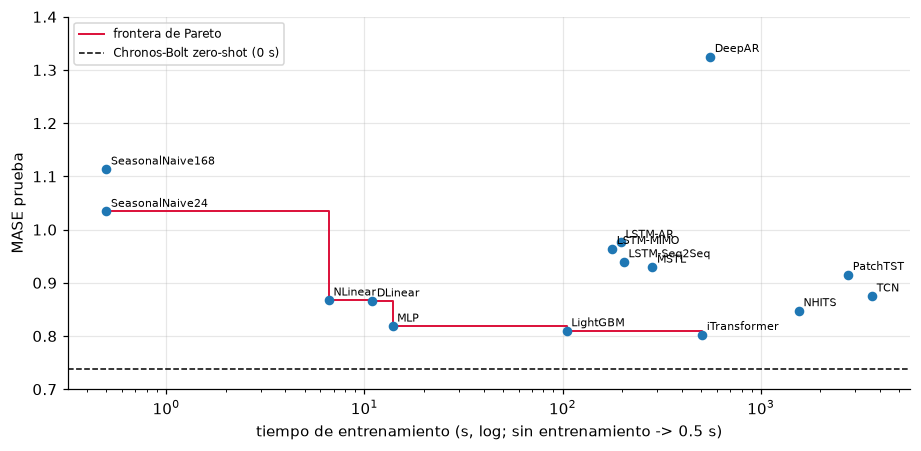

frontera: SeasonalNaive24 (1.034) -> NLinear (0.868) -> DLinear (0.866) -> MLP (0.819) -> LightGBM (0.810) -> iTransformer (0.803)


In [31]:
# (1) Frontera de Pareto: MASE vs. tiempo de entrenamiento (log). Chronos (sin entrenamiento) y el
# naive (MASE 4) se muestran como referencia para no aplastar la escala.
t = table[~table.model.isin(["Chronos-Bolt", "Naive"])].copy()
t["train_plot"] = t.train_s.fillna(0).clip(lower=0.5)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.scatter(t.train_plot, t.MASE, s=28, zorder=3)
for _, r in t.iterrows():
    ax.annotate(r.model, (r.train_plot, r.MASE), fontsize=7, xytext=(3, 3), textcoords="offset points")
ts = t.sort_values("train_plot"); front = ts[ts.MASE <= ts.MASE.cummin()]
ax.step(front.train_plot, front.MASE, where="post", color="crimson", lw=1.3, label="frontera de Pareto")
ax.axhline(table.set_index("model").loc["Chronos-Bolt", "MASE"], ls="--", color="k", lw=1, label="Chronos-Bolt zero-shot (0 s)")
ax.set(xscale="log", xlabel="tiempo de entrenamiento (s, log; sin entrenamiento -> 0.5 s)", ylabel="MASE prueba", ylim=(0.7, 1.4))
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / "pareto.png", bbox_inches="tight"); plt.show()
print("frontera:", " -> ".join(f"{r.model} ({r.MASE:.3f})" for _, r in front.iterrows()))

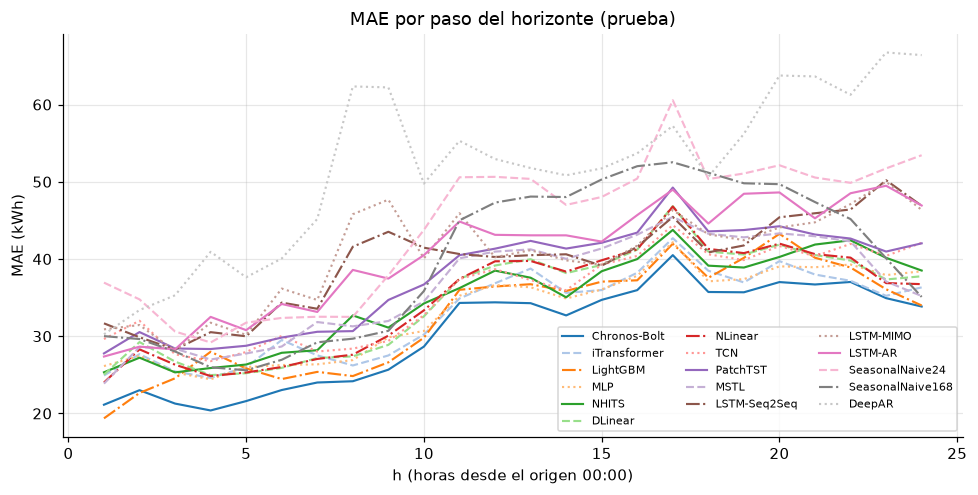

In [32]:
# (2) MAE por paso del horizonte, una curva por modelo
fig, ax = plt.subplots(figsize=(9, 4.6))
colors, styles = plt.cm.tab20(np.linspace(0, 1, 20)), ["-", "--", "-.", ":"]
for k, n in enumerate(table.model):
    if n == "Naive": continue
    r = load_run(n); m = metrics(r["F"], r["A"], P.scale)
    ax.plot(range(1, 25), m["MAE_by_h"], lw=1.4, color=colors[k % 20], ls=styles[k % 4], label=n)
ax.set(xlabel="h (horas desde el origen 00:00)", ylabel="MAE (kWh)", title="MAE por paso del horizonte (prueba)")
ax.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.savefig(FIG / "mae_by_h.png", bbox_inches="tight"); plt.show()

Como todos los orígenes son a las 00:00, el paso *h* coincide con la hora del día *h−1*: el
error por hora del día es la misma curva desplazada (se calcula explícitamente abajo). La
forma de la curva mezcla dos efectos: degradación con el horizonte y dificultad propia de
cada hora (las horas de arranque de actividad, 7–10 h, son las más difíciles).

In [33]:
hod = pd.DataFrame({n: by_hour_of_day(load_run(n)["F"], load_run(n)["A"], load_run(n)["origins"], idx)
                    for n in table.model[:6]})
hod.index.name = "hora"; hod.round(2).T

hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Chronos-Bolt,21.129999,23.010000,21.280001,20.389999,21.600000,23.030001,24.010000,24.170000,25.670000,28.660000,...,34.709999,35.970001,40.500000,35.730000,35.689999,37.009998,36.700001,37.029999,34.930000,33.849998
iTransformer,24.910000,27.670000,25.440001,24.610001,25.980000,29.510000,27.520000,26.209999,27.510000,30.219999,...,35.980000,38.220001,42.700001,38.480000,36.959999,39.720001,37.990002,37.180000,35.230000,36.330002
LightGBM,19.370001,22.650000,24.549999,27.990000,25.830000,24.450001,25.379999,24.840000,26.620001,29.809999,...,37.070000,37.240002,41.970001,37.570000,40.150002,43.259998,40.160000,38.900002,36.080002,33.980000
MLP,26.129999,27.459999,25.290001,24.420000,26.010000,26.270000,26.360001,26.910000,29.860001,30.680000,...,36.049999,37.820000,42.169998,37.110001,37.389999,39.049999,38.930000,39.279999,37.919998,38.410000
NHITS,25.330000,27.219999,25.320000,25.879999,26.330000,27.850000,28.190001,32.689999,31.110001,34.250000,...,38.419998,39.990002,43.770000,39.139999,38.900002,40.270000,41.869999,42.419998,40.150002,38.500000
DLinear,25.020000,29.240000,26.719999,24.959999,25.209999,25.900000,27.180000,27.389999,28.879999,32.570000,...,39.230000,41.209999,46.849998,40.950001,40.580002,41.860001,40.509998,39.799999,37.349998,37.770000


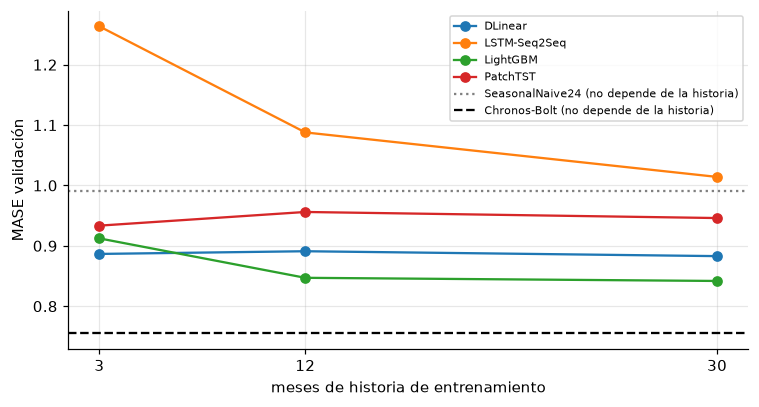

In [34]:
# (3) MASE vs. meses de historia (validación) con Chronos como referencia
itv = pd.read_csv(ITER_CSV)
base30 = ["DLinear_L168_H24_m30_series_h128_l2_d0.1_lr0.001_b512_s42",            # 30 meses (corrida base)
          "LSTM-Seq2Seq_L168_H24_m30_series_h128_l2_d0.1_lr0.001_b512_s42"]
hist = itv[(itv.group == "history") | itv.tag.isin(base30)]
fig, ax = plt.subplots(figsize=(7, 3.8))
for m, g in hist.groupby("model"):
    g = g.sort_values("months"); ax.plot(g.months, g.best_val_MASE, marker="o", label=m)
for n, ls in (("SeasonalNaive24", ":"), ("Chronos-Bolt", "--")):
    try:
        rv = load_run(n, "val"); ax.axhline(metrics(rv["F"], rv["A"], P.scale)["MASE"], ls=ls, color="gray" if "Naive" in n else "k", label=f"{n} (no depende de la historia)")
    except FileNotFoundError: pass
ax.set(xlabel="meses de historia de entrenamiento", ylabel="MASE validación", xticks=[3, 12, 30]); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "history.png", bbox_inches="tight"); plt.show()

### 6.1 Resultados probabilísticos

,model,MAE,MASE,pinball,coverage_80
0,Chronos-Bolt,30.4473,0.7374,10.5833,0.7983
15,DeepAR,51.6365,1.3253,18.3556,0.5527


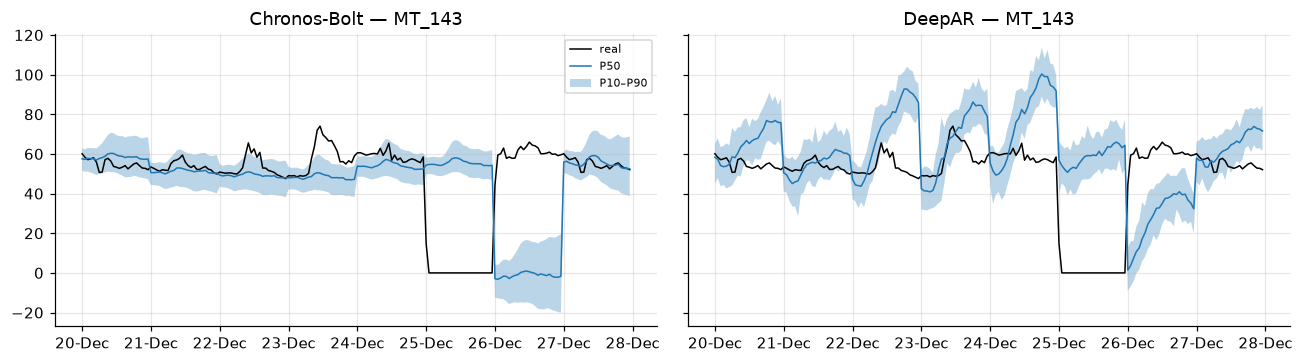

In [35]:
prob = table.dropna(subset=["pinball"])[["model", "MAE", "MASE", "pinball", "coverage_80"]]
display(prob.round(4))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
i = int(np.argsort(P.Y[:P.t_train_end].mean(0))[P.N // 2])        # cliente mediano
for a, n in zip(axs, prob.model):
    r = load_run(n); o = slice(80, 88)                               # 20-27 dic
    tt = np.concatenate([np.arange(t0, t0 + 24) for t0 in r["origins"][o]])
    a.plot(idx[tt], r["A"][i, o].ravel(), "k", lw=1, label="real")
    a.plot(idx[tt], r["Q"][i, o, :, 1].ravel(), lw=1, label="P50")
    a.fill_between(idx[tt], r["Q"][i, o, :, 0].ravel(), r["Q"][i, o, :, 2].ravel(), alpha=.3, label="P10–P90")
    a.set_title(f"{n} — {P.columns[i]}"); a.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
axs[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG / "probabilistic.png", bbox_inches="tight"); plt.show()

### 6.2 Semana del 22 al 28 de diciembre, reentrenamiento mensual y semillas

Reentrenamiento: iTransformer (mejor DL entrenado) y LightGBM se reentrenan el 1 de oct, nov y
dic con toda la historia disponible (ventana expandible). MSTL no se repite: StatsForecast ya lo
reajusta en cada origen aun con `refit=False` (su `forward` re-descompone la serie), por lo que el
resultado sería idéntico.

In [36]:
xm = table[["model", "MASE", "MASE_xmas"]].assign(deterioro=lambda d: d.MASE_xmas / d.MASE - 1)
display(xm.round(3))

,model,MASE,MASE_xmas,deterioro
0,Chronos-Bolt,0.737,1.336,0.812
1,iTransformer,0.803,1.278,0.592
2,LightGBM,0.810,1.411,0.742
3,MLP,0.819,1.457,0.780
4,NHITS,0.848,1.396,0.647
5,DLinear,0.866,1.821,1.103
6,NLinear,0.868,1.819,1.097
7,TCN,0.875,1.586,0.812
8,PatchTST,0.916,1.774,0.938
9,MSTL,0.929,2.060,1.216


In [37]:
rt = []
for n in list_runs("retrain"):
    r = load_run(n, "retrain"); base = r["meta"]["base"]
    once = table.set_index("model").loc[base, "MASE"] if base in set(table.model) else np.nan
    rt.append(dict(modelo=base, MASE_una_vez=once, MASE_reentreno_mensual=metrics(r["F"], r["A"], P.scale)["MASE"]))
pd.DataFrame(rt).round(4)

,modelo,MASE_una_vez,MASE_reentreno_mensual
0,LightGBM,0.8098,0.8048
1,iTransformer,0.8028,0.8182


In [38]:
for f in ("seeds.csv", "seeds_itransformer.csv"):
    sd = pd.read_csv(C.RESULTS_DIR / f)
    print(f"{sd.model.iloc[0]:13s} MASE prueba por semilla:", dict(zip(sd.seed, sd.test_MASE.round(4))),
          f"-> {sd.test_MASE.mean():.4f} ± {sd.test_MASE.std(ddof=1):.4f}")

MLP           MASE prueba por semilla: {42: 0.8185, 43: 0.812, 44: 0.8045} -> 0.8117 ± 0.0070
iTransformer  MASE prueba por semilla: {42: 0.8028, 43: 0.8224, 44: 0.8118} -> 0.8123 ± 0.0098


### 6.3 Archivo de pronósticos de prueba

In [39]:
fc_long = pd.concat([to_long_forecasts(load_run(n), idx, P.columns) for n in table.model], ignore_index=True)
fc_long["y_hat"] = fc_long.y_hat.round(3)
out = C.RESULTS_DIR / "forecasts_test.csv.gz"
fc_long.to_csv(out, index=False, compression="gzip")
print(out.name, fc_long.shape, "|", fc_long.modelo.nunique(), "modelos"); fc_long.head()

forecasts_test.csv.gz (3753600, 4) | 17 modelos


,unique_id,ds,modelo,y_hat
0,MT_013,2014-10-01 00:00:00,Chronos-Bolt,51.008999
1,MT_013,2014-10-01 01:00:00,Chronos-Bolt,52.205002
2,MT_013,2014-10-01 02:00:00,Chronos-Bolt,50.417000
3,MT_013,2014-10-01 03:00:00,Chronos-Bolt,47.939999
4,MT_013,2014-10-01 04:00:00,Chronos-Bolt,50.039001


## 8. Discusión y análisis

**¿Qué modelo ganó y por cuánto superó al seasonal naive?** El mejor fue **Chronos-Bolt
zero-shot** (MASE 0.737, WAPE 5.9 %), 29 % mejor que el seasonal naive de 24 h (1.034) y 34 % mejor
que el de 168 h (1.114). Entre los modelos entrenados ganó **iTransformer** (0.803), seguido muy de
cerca por **LightGBM** (0.810) y nuestro **MLP** (0.819): la diferencia entre los tres (≤ 0.016) es del
orden de la desviación por semilla (iTransformer 0.812 ± 0.010; MLP 0.812 ± 0.007), así que en la
práctica empatan. En costo, el MLP entrena en 14 s y LightGBM en 105 s, contra 8.5 min de
iTransformer y 26–61 min de N-HiTS/TCN en CPU. En producción la mejora de ~22 % sobre el naive sí
justifica un modelo, pero no uno caro: LightGBM o el MLP están en la frontera de Pareto y son fáciles
de reentrenar; Chronos no se entrena pero exige ~205 M de parámetros e inferencia de 66 s por backtest.

**¿Se replica el hallazgo de DLinear?** Sí. Con H = 24, DLinear (0.866) y NLinear (0.868), con 16 k y
8 k parámetros, superan a PatchTST (0.916, 445 k parámetros y 46 min) y a MSTL; solo iTransformer, que
explota la correlación entre clientes, queda por delante. Con H = 168 la ventaja es todavía más
clara: DLinear 0.984, NLinear 0.994 y MLP 0.993 frente a Chronos 0.917 y seasonal naive 1.119.

**Estrategias multi-paso.** Con el mismo presupuesto (40 épocas) el **encoder–decoder** fue la mejor
(val 0.971; prueba 0.939), seguido de multi-salida (0.997 / 0.964) y autorregresiva (1.004 / 0.976).
La autorregresiva muestra la acumulación de errores: es la **mejor en h = 1** (MASE por paso 0.66 vs
0.74–0.77), porque su objetivo de entrenamiento es justamente el paso siguiente, pero a partir de
h ≈ 9–12 queda por encima de las otras dos (1.11 vs 1.02 en h = 12) al realimentar sus propios errores. El decoder que realimenta su predicción con teacher forcing al 50 % fue el peor (1.022): la
*exposure bias* le cuesta más de lo que aporta. El decoder no autorregresivo, que solo recibe el
calendario futuro, evita el problema y aprovecha las covariables. En todas las familias el error
crece con *h*, mezclado con la dificultad de cada hora del día (el máximo se da entre 14 y 19 h, donde
la carga es mayor y más variable, y baja de nuevo hacia h = 24). Los modelos que ven el último valor
(LightGBM, Chronos, iTransformer) arrancan muy bajo (MASE 0.48–0.56 en h = 1); DeepAR, que muestrea
trayectorias autorregresivas, casi duplica su error en el horizonte (0.78 → 1.58).

**Ventana L, normalización e historia.** Una L más larga ayudó a los lineales y al MLP (DLinear
0.958 → 0.883 → 0.862 con L = 48/168/336) pero no a la LSTM (1.014 con 168 vs 1.077 con 336: la
recurrencia olvida). La **normalización global** fue la peor en ambos modelos (DLinear 1.171, LSTM
1.752) porque los clientes grandes dominan la pérdida; z-score por serie y RevIN quedaron
prácticamente igual (0.883 vs 0.887). La historia importa mucho para la LSTM (1.264 → 1.088 → 1.014
con 3/12/30 meses) y para LightGBM (0.912 → 0.847 → 0.842), poco para DLinear (≈ 0.89) y nada para
PatchTST (0.93–0.96). Con 3 meses DLinear supera a LightGBM; desde 12 meses LightGBM supera a DLinear, la LSTM y
PatchTST en validación, y solo el MLP con 30 meses (0.818) lo supera; en prueba lo igualan el MLP e
iTransformer. Ningún modelo
de DL entrenado alcanzó a Chronos (0.755 en validación).

**¿Global o local?** El **global** ganó: MASE 0.858 contra 0.911 en los 10 clientes. Los que más se
benefician son clientes con series ruidosas o con cambios de régimen (MT_247, MT_268, MT_319,
MT_360: 11–14 % de mejora), que con su propia historia sobreajustan; los clientes muy regulares
(MT_046, MT_050, MT_279) quedan igual.

**Chronos zero-shot.** Quedó **por delante** de todos los modelos entrenados y además entrega
cuantiles bien calibrados (cobertura P10–P90 = 79.8 % ≈ 80 %, pinball 10.6 frente a 18.4 de DeepAR).
Lo usaríamos cuando no hay tiempo o datos para entrenar (clientes nuevos, arranque en frío, muchas
series heterogéneas) o como baseline fuerte antes de invertir en un modelo propio. Un modelo
entrenado conviene cuando hay covariables propias (clima, tarifas) o la latencia/costo de inferencia
importan.

**Navidad y Año Nuevo.** El 25-dic el consumo cae 36–54 % respecto a la segunda semana de diciembre.
En la semana del 22 al 28 de diciembre **todos** los modelos empeoran (MASE ×1.4 a ×2.2). Los que
tienen la bandera de feriado o usan el calendario (iTransformer 1.28, Chronos 1.34, N-HiTS 1.40,
LightGBM 1.41, LSTM 1.47) degradan mucho menos que los que no lo usan (DLinear/NLinear 1.82, MSTL 2.06,
seasonal naive 24 h 2.17). La covariable ayuda, pero con solo dos Navidades en el entrenamiento el
cambio de régimen sigue dominando el error.

**Reentrenamiento mensual.** Reentrenar el 1 de cada mes con ventana expandible casi no cambió el
error: LightGBM 0.810 → 0.805 y iTransformer 0.803 → 0.818 (dentro de la variación por semilla). Tres
meses no son suficientes para que la deriva de la serie haga necesario reentrenar.

**Sensibilidad a la semilla.** MLP: 0.8117 ± 0.0070; iTransformer: 0.8123 ± 0.0098 (3 semillas). Las
diferencias menores a ~0.01–0.02 de MASE entre modelos no deben interpretarse como significativas.

**Correlación entrenamiento–validación.** Una pérdida de entrenamiento más baja no implica siempre un
mejor MASE de validación (Spearman 0.65 entre ambas): el caso más claro es la
**LSTM autorregresiva**, que tiene la menor pérdida de entrenamiento de todas las iteraciones (0.163)
y un MASE de validación de 1.004, contra 0.204 y 0.819 del mejor MLP. Su pérdida se mide con teacher
forcing (un paso adelante con el valor real), que no refleja el error al realimentar sus propias
predicciones; lo mismo le pasa al seq2seq que realimenta y (0.194 → 1.022). Dentro de una misma
arquitectura sí hay relación, pero entre arquitecturas la pérdida de entrenamiento no predice el MASE.